# Hierarchical (Agglomerative) Customer Segmentation

This notebook clusters the prepared five-component PCA data without rescaling it. Ward linkage is selected for the final model because it produces useful, reasonably sized customer segments rather than tiny outlier groups.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score, silhouette_score

BASE = "../data/processed/"
Z = pd.read_csv(BASE + "customer_pca.csv", index_col="CustomerID")
info = pd.read_csv(BASE + "customer_features.csv", index_col="CustomerID").loc[Z.index]
Z.head()

,PC1,PC2,PC3,PC4,PC5
CustomerID,,,,,
12346,-2.734894,-2.991986,2.132441,0.998034,0.468937
12347,3.589612,2.281717,-1.242719,-0.382392,-0.807583
12348,1.228287,0.845236,-0.985068,-0.459783,0.898431
12349,0.553772,5.872273,1.939445,0.008892,-0.733261
12350,-2.660162,0.845008,0.680010,0.214199,0.409236


## Linkage comparison

All methods are evaluated with four clusters so that the comparison is like-for-like.

In [2]:
linkage_results = []
for method in ["ward", "complete", "average", "single"]:
    model = AgglomerativeClustering(n_clusters=4, linkage=method)
    labels = model.fit_predict(Z)
    counts = pd.Series(labels).value_counts().sort_index()
    linkage_results.append({
        "linkage": method,
        "cluster_sizes": ", ".join(str(int(x)) for x in counts),
        "silhouette": silhouette_score(Z, labels),
        "davies_bouldin": davies_bouldin_score(Z, labels),
    })
comparison = pd.DataFrame(linkage_results).set_index("linkage")
comparison.round(3)

,cluster_sizes,silhouette,davies_bouldin
linkage,,,
ward,"1396, 1093, 1370, 284",0.330,1.182
complete,"119, 4015, 8, 1",0.270,0.992
average,"4128, 6, 8, 1",0.571,0.475
single,"3, 4138, 1, 1",0.698,0.273


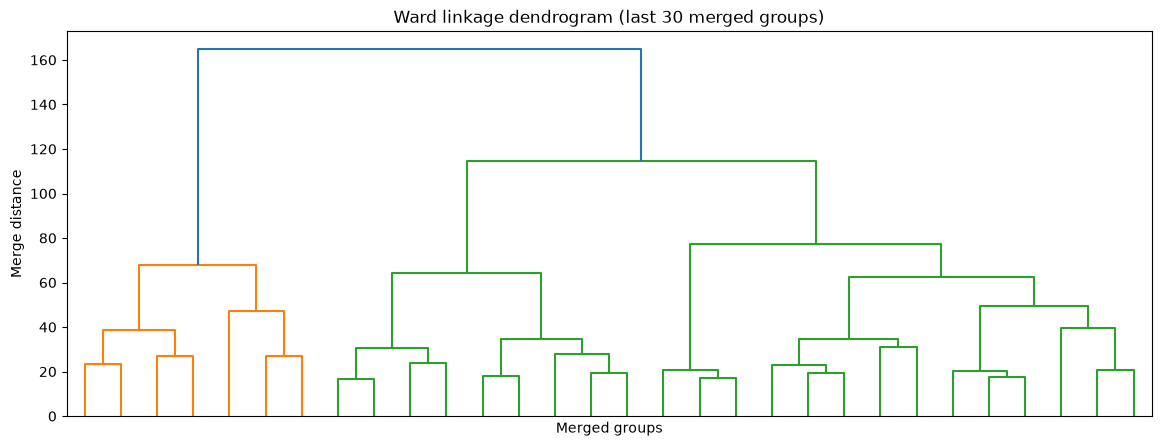

In [3]:
ward_tree = linkage(Z, method="ward")
plt.figure(figsize=(14, 5))
dendrogram(ward_tree, truncate_mode="lastp", p=30, no_labels=True, color_threshold=None)
plt.title("Ward linkage dendrogram (last 30 merged groups)")
plt.xlabel("Merged groups")
plt.ylabel("Merge distance")
plt.show()

The largest useful cut is four clusters. Ward is preferred over single and average despite their higher silhouette scores: those methods put nearly every customer in one cluster and use the score to reward separation of a few tiny groups. Complete linkage also creates one dominant cluster.

In [4]:
k = 4
linkage_method = "ward"
hc = AgglomerativeClustering(n_clusters=k, linkage=linkage_method)
labels = hc.fit_predict(Z)
np.save("labels_hierarchical.npy", labels)

sizes = pd.Series(labels, name="customers").value_counts().sort_index()
metrics = pd.Series({
    "number_of_clusters": sizes.size,
    "silhouette": silhouette_score(Z, labels),
    "davies_bouldin": davies_bouldin_score(Z, labels),
})
print("Cluster sizes:")
display(sizes.to_frame())
display(metrics.to_frame("value"))

Cluster sizes:


,count
customers,
0,1396
1,1093
2,1370
3,284


,value
number_of_clusters,4.000000
silhouette,0.330360
davies_bouldin,1.181981


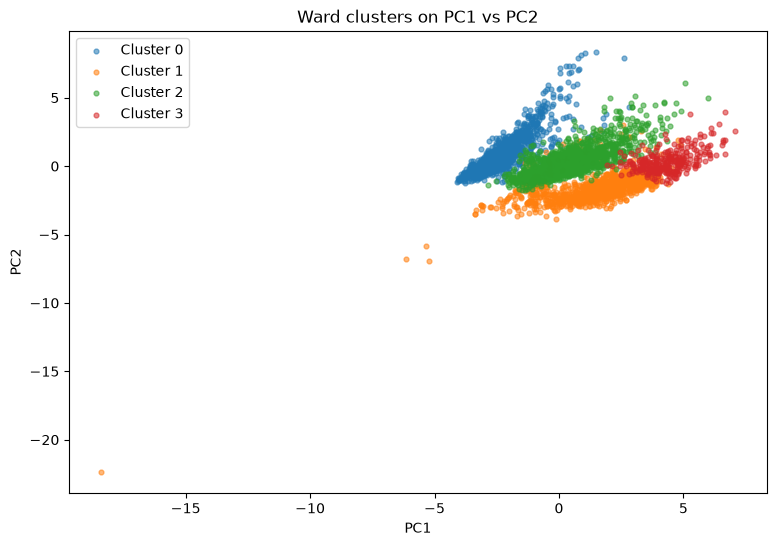

In [5]:
plot_data = Z.assign(cluster=labels)
plt.figure(figsize=(9, 6))
for cluster, group in plot_data.groupby("cluster"):
    plt.scatter(group.PC1, group.PC2, s=12, alpha=0.55, label=f"Cluster {cluster}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Ward clusters on PC1 vs PC2")
plt.legend()
plt.show()

In [6]:
profile_columns = [
    "Recency_Days", "N_Invoices", "Total_Quantity", "Total_Spend",
    "Unique_Products", "Avg_Invoice_Value", "Avg_Days_Between_Purchases",
    "N_Cancellations", "Cancellation_Rate", "Monthly_Spend_Mean",
    "Monthly_Spend_Std", "Spend_Trend"
]
profiles = info.assign(cluster=labels).groupby("cluster")[profile_columns].median()
cluster_names = {
    0: "Recent high-value repeat buyers",
    1: "Established regular buyers",
    2: "Low-frequency buyers",
    3: "Large-basket mixed buyers",
}
profiles.insert(0, "segment_name", profiles.index.map(cluster_names))
profiles.round(2)

,segment_name,Recency_Days,N_Invoices,Total_Quantity,Total_Spend,Unique_Products,Avg_Invoice_Value,Avg_Days_Between_Purchases,N_Cancellations,Cancellation_Rate,Monthly_Spend_Mean,Monthly_Spend_Std,Spend_Trend
cluster,,,,,,,,,,,,,
0,Recent high-value repeat buyers,116.0,1.0,143.0,245.90,16.0,232.54,0.00,0.0,0.00,245.28,0.00,0.00
1,Established regular buyers,35.0,5.0,522.0,948.96,45.0,181.67,48.25,1.0,0.33,286.62,141.40,0.00
2,Low-frequency buyers,37.0,3.0,463.0,790.35,45.0,243.98,72.00,0.0,0.00,288.30,95.88,-0.61
3,Large-basket mixed buyers,15.0,11.0,2267.0,3968.68,132.0,375.83,40.06,2.0,0.18,612.53,331.68,6.52


## Sensitivity to extreme customers

The optional all-customer file contains the 219 customers held out as extreme. The same four-cluster experiment shows whether a linkage method absorbs them or makes them tiny clusters.

In [7]:
A = pd.read_csv(BASE + "customer_pca_all.csv", index_col="CustomerID")
P = A.drop(columns="IsOutlier")
noise_rows = []
for method in ["ward", "complete", "average", "single"]:
    all_labels = AgglomerativeClustering(n_clusters=4, linkage=method).fit_predict(P)
    counts = pd.Series(all_labels).value_counts().sort_index()
    outlier_counts = pd.Series(all_labels[A.IsOutlier]).value_counts().sort_index()
    noise_rows.append({
        "linkage": method,
        "all_cluster_sizes": ", ".join(str(int(x)) for x in counts),
        "outliers_by_cluster": ", ".join(str(int(x)) for x in outlier_counts.reindex(counts.index, fill_value=0)),
    })
noise_test = pd.DataFrame(noise_rows).set_index("linkage")
noise_test

,all_cluster_sizes,outliers_by_cluster
linkage,,
ward,"836, 2111, 1404, 11","185, 15, 8, 11"
complete,"4354, 2, 4, 2","211, 2, 4, 2"
average,"11, 4347, 2, 2","11, 204, 2, 2"
single,"4358, 2, 1, 1","215, 2, 1, 1"


## Interpretation

- **Shape:** Ward produces four visibly separated but overlapping groups in the PC1/PC2 projection; the remaining PCA dimensions are still used for clustering.
- **Sensitivity:** adding the 219 extreme customers changes Ward's group sizes substantially, but does not create a dedicated outlier cluster. Single and average remain dominated by one large cluster, while complete isolates only a few customers.
- **Strengths:** hierarchical clustering gives a dendrogram, needs no random seed, and exposes the effect of different linkage assumptions.
- **Weaknesses:** it requires a fixed cut, is sensitive to linkage and extreme observations, and does not provide a built-in noise label.
- **When to use:** use Ward here when balanced, interpretable segments are the goal; use single/average only when chaining or rare-point separation is specifically desired, and use a noise-aware method when outliers must be identified explicitly.